# Lab 2: Taking the Temperature of a Cold Brown Dwarf
ASTR 3986: Astrostatistics

Goal: fit a blackbody (Planck function) model to photometry of WISE 0855-0714 and use MCMC (Metropolis algorithm) to get the posterior on temperature T (and scale factor alpha).

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Part 1: Model, $\chi^2$/Likelihood, and Priors

**Model**

$$\log_{10} f(\lambda, T, \log_{10}\alpha) = \log_{10}\alpha + \log_{10}\!\left(\frac{2hc^2}{\lambda^5}\right) - \log_{10}\!\left[\exp\!\left(\frac{hc}{\lambda k_B T}\right) - 1\right]$$

Parameters: $\Theta = (T, \log_{10}\alpha)$.

**$\chi^2$**

$$\chi^2(\Theta) = \sum_{i=1}^N \left(\frac{y_i - \log_{10} f(\lambda_i;\Theta)}{\sigma_i}\right)^2$$

where $y_i$ = `log_flux`, $\sigma_i$ = `log_flux_err`.

**Log-likelihood**

$$\log\mathcal{L}(\Theta) = -\frac{1}{2}\chi^2(\Theta) - \sum_{i=1}^N\log\sigma_i - \frac{N}{2}\log(2\pi)$$

**Priors (flat/uniform, bounded)**

$$\pi(T) \propto 1 \text{ for } T\in[T_{\min},T_{\max}], \qquad \pi(\log_{10}\alpha) \propto 1 \text{ for } \log_{10}\
\in[\log_{10}\alpha_{\min},\log_{10}\alpha_{\max}]$$

(zero outside the bounds)

**Log-posterior**

$$\log\mathcal{P}(\Theta) = \log\pi(T) + \log\pi(\log_{10}\alpha) + \log\mathcal{L}(\Theta)$$

## 2) Import data

Load data.dat (columns: wavelength [microns], log10(flux), error on log10(flux)).

In [11]:
wavelength, log_flux, log_flux_err = np.loadtxt('data.dat', skiprows=7, unpack=True)

df = pd.read_csv('data.dat', sep=r'\s+', skiprows=7,
                  names=['wavelength_um', 'log_flux', 'log_flux_err'])
print(df.head())


   wavelength_um   log_flux  log_flux_err
0          3.368 -18.434869      0.086859
1          4.618 -17.042091      0.086859
2         12.082 -15.727552      0.086859
3         22.194 -16.307417      0.086859
4          3.600 -18.062511      0.043429


## 3) Model + log-likelihood/log-prior/log-posterior functions

Tip: plot data vs. model curve for a guess set of parameters and check chi^2 before sampling.

In [12]:
# Defining physical constants, cgs units
H_CGS = 6.62607015e-27   # erg s
C_CGS = 2.99792458e10    # cm / s
KB_CGS = 1.380649e-16    # erg / K

# Prior bounds
T_BOUNDS = (50.0, 1000.0)
LOG_ALPHA_BOUNDS = (-40.0, 0.0)


def log_model(wavelength, T, alpha):
    """log10(Planck function) in the same units as the data.
    wavelength : wavelength [microns]
    T          : temperature [K]
    alpha      : log10 of the multiplicative scale factor
    """
    lam_cm = wavelength * 1e-4
    x = H_CGS * C_CGS / (lam_cm * KB_CGS * T)
    log_prefactor = np.log10(2.0 * H_CGS * C_CGS**2) - 5.0 * np.log10(lam_cm)
    log_denom = np.log10(np.expm1(x))
    log_planck = log_prefactor - log_denom
    return alpha + log_planck


In [13]:
def log_prior(params):
    """Flat priors on T and log_alpha within fixed bounds."""
    T, log_alpha = params
    if not (T_BOUNDS[0] < T < T_BOUNDS[1]):
        return -np.inf
    if not (LOG_ALPHA_BOUNDS[0] < log_alpha < LOG_ALPHA_BOUNDS[1]):
        return -np.inf
    return 0.0


In [14]:
def log_likelihood(params, wavelength, log_flux, log_flux_err):
    """Gaussian log-likelihood comparing log_model(...) to the observed log_flux."""
    T, log_alpha = params
    model = log_model(wavelength, T, log_alpha)
    resid = (log_flux - model) / log_flux_err
    return -0.5 * np.sum(resid**2 + np.log(2.0 * np.pi * log_flux_err**2))


In [15]:
def log_posterior(params, wavelength, log_flux, log_flux_err):
    lp = log_prior(params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params, wavelength, log_flux, log_flux_err)


theta0: T = 785.3 K, log_alpha = -22.44
chi^2          = 38425.72
log-likelihood = -19202.33
log-prior      = 0.00
log-posterior  = -19202.33


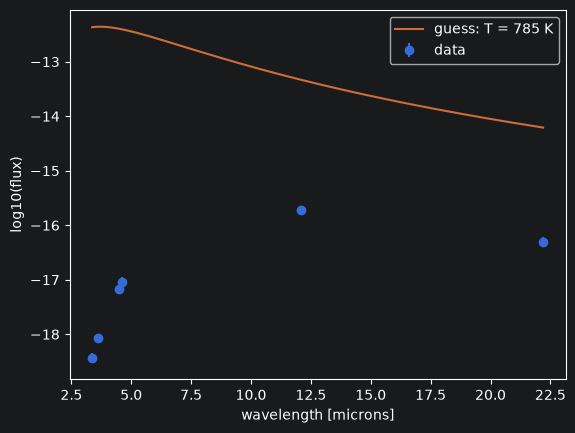

In [16]:
def chi_squared(params, wavelength, log_flux, log_flux_err):
    """Raw chi^2, useful as a standalone goodness-of-fit check."""
    T, log_alpha = params
    model = log_model(wavelength, T, log_alpha)
    return np.sum(((log_flux - model) / log_flux_err) ** 2)


rng = np.random.default_rng(42)

T0 = rng.uniform(*T_BOUNDS)
log_alpha0 = rng.uniform(*LOG_ALPHA_BOUNDS)
theta0 = np.array([T0, log_alpha0])

chi2_0 = chi_squared(theta0, wavelength, log_flux, log_flux_err)
ll0 = log_likelihood(theta0, wavelength, log_flux, log_flux_err)
lp0 = log_prior(theta0)
lpost0 = log_posterior(theta0, wavelength, log_flux, log_flux_err)

print(f"theta0: T = {T0:.1f} K, log_alpha = {log_alpha0:.2f}")
print(f"chi^2          = {chi2_0:.2f}")
print(f"log-likelihood = {ll0:.2f}")
print(f"log-prior      = {lp0:.2f}")
print(f"log-posterior  = {lpost0:.2f}")

fig, ax = plt.subplots()
ax.errorbar(wavelength, log_flux, yerr=log_flux_err, fmt="o", label="data")

lam_grid = np.linspace(wavelength.min(), wavelength.max(), 200)
ax.plot(lam_grid, log_model(lam_grid, T0, log_alpha0), label=f"guess: T = {T0:.0f} K")

ax.set_xlabel("wavelength [microns]")
ax.set_ylabel("log10(flux)")
ax.legend()
plt.show()


Comment:f

## 4) Metropolis sampler

Initialize at a random point, walk using the Metropolis rule with Gaussian proposals.

In [18]:
def run_metropolis(log_posterior_fn, start, proposal_sigma, n_steps, seed=0, args=()):
    rng = np.random.default_rng(seed)
    start = np.atleast_1d(np.asarray(start, dtype=float))
    ndim = start.size
    proposal_sigma = np.atleast_1d(np.asarray(proposal_sigma, dtype=float))

    chain = np.empty((n_steps + 1, ndim))
    log_post_chain = np.empty(n_steps + 1)

    chain[0] = start
    log_post_chain[0] = log_posterior_fn(start, *args)

    n_accept = 0
    for i in range(n_steps):
        current, current_log_post = chain[i], log_post_chain[i]

        trial = current + rng.normal(0.0, proposal_sigma, size=ndim)
        trial_log_post = log_posterior_fn(trial, *args)

        log_accept_ratio = trial_log_post - current_log_post
        if np.log(rng.uniform()) < log_accept_ratio:
            chain[i + 1] = trial
            log_post_chain[i + 1] = trial_log_post
            n_accept += 1
        else:
            chain[i + 1] = current
            log_post_chain[i + 1] = current_log_post

    accept_rate = n_accept / n_steps
    return chain, log_post_chain, accept_rate



## 5) Tune jump sizes / priors

Run a short chain, check acceptance rate, adjust proposal_sigma and priors as needed.

proposal_sigma = [5.  0.1], acceptance rate = 22.15%
proposal_sigma = [20.   0.5], acceptance rate = 3.35%
proposal_sigma = [50.  1.], acceptance rate = 1.15%
proposal_sigma = [100.   2.], acceptance rate = 0.60%
0.1878
proposal_sigma = [5.  0.1], acceptance rate = 18.78%


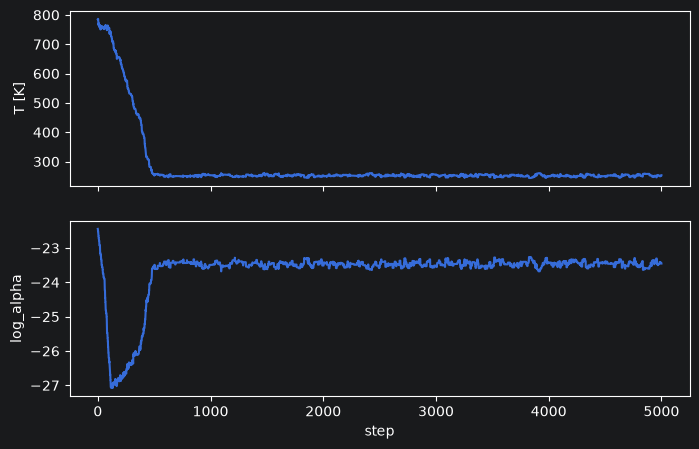

In [21]:
def try_proposal(proposal_sigma, n_steps=2000, seed=0):
    chain, log_post_chain, accept_rate = run_metropolis(
        log_posterior, theta0, proposal_sigma, n_steps,
        seed=seed, args=(wavelength, log_flux, log_flux_err),
    )
    print(f"proposal_sigma = {proposal_sigma}, acceptance rate = {accept_rate:.2%}")
    return chain, log_post_chain, accept_rate


# try a few candidate jump sizes [sigma_T, sigma_log_alpha] and compare acceptance
for sigma_T, sigma_log_alpha in [(5, 0.1), (20, 0.5), (50, 1.0), (100, 2.0)]:
    try_proposal(np.array([sigma_T, sigma_log_alpha]), n_steps=2000)


# look at the trace to check it's actually exploring (not stuck / not jittering wildly)
proposal_sigma = np.array([5, 0.1])  #best choice from above
chain, log_post_chain, accept_rate = try_proposal(proposal_sigma, n_steps=5000)

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].plot(chain[:, 0])
axes[0].set_ylabel("T [K]")
axes[1].plot(chain[:, 1])
axes[1].set_ylabel("log_alpha")
axes[1].set_xlabel("step")
plt.show()

## 6) Filter burn-in

acceptance rate: 17.06%
kept 49001 of 50001 samples after burn-in


Text(0.5, 0, 'step')

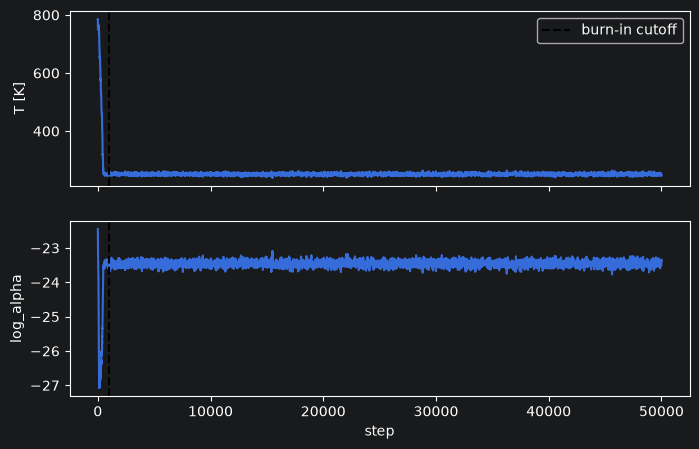

In [24]:
n_steps = 50000
chain, log_post_chain, accept_rate = run_metropolis(
    log_posterior, theta0, proposal_sigma, n_steps,
    seed=0, args=(wavelength, log_flux, log_flux_err),
)
print(f"acceptance rate: {accept_rate:.2%}")

burn_in = 1000  # chosen by eye from the Part 5 trace plot (settled by ~step 500-600)

chain_post = chain[burn_in:]
log_post_chain_post = log_post_chain[burn_in:]

print(f"kept {len(chain_post)} of {len(chain)} samples after burn-in")

# visually confirm the burn-in cutoff against the full trace
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)

axes[0].plot(chain[:, 0])
axes[0].axvline(burn_in, color="k", linestyle="--", label="burn-in cutoff")
axes[0].set_ylabel("T [K]")
axes[0].legend()

axes[1].plot(chain[:, 1])
axes[1].axvline(burn_in, color="k", linestyle="--")
axes[1].set_ylabel("log_alpha")
axes[1].set_xlabel("step")


## 7) Diagnostic plots

- Trace plot (burn-in visible)
- Mixing (e.g. running mean / autocorrelation)
- Posterior histograms for T and alpha

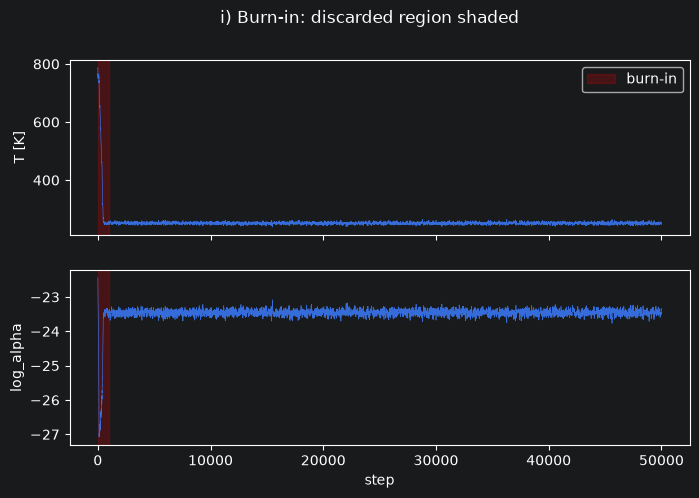

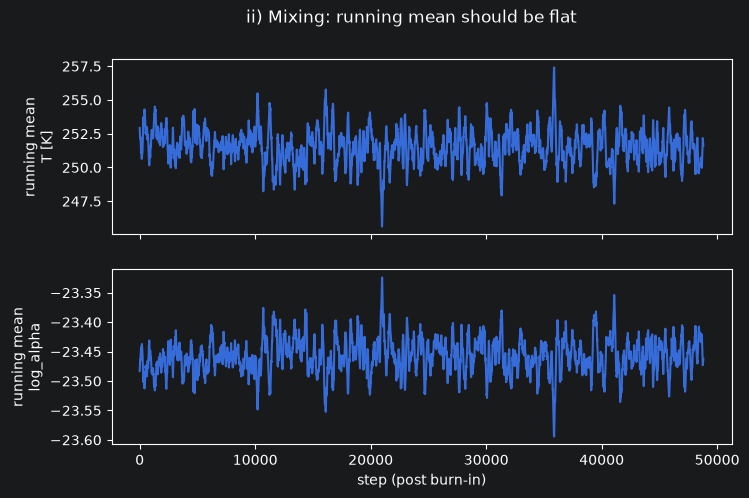

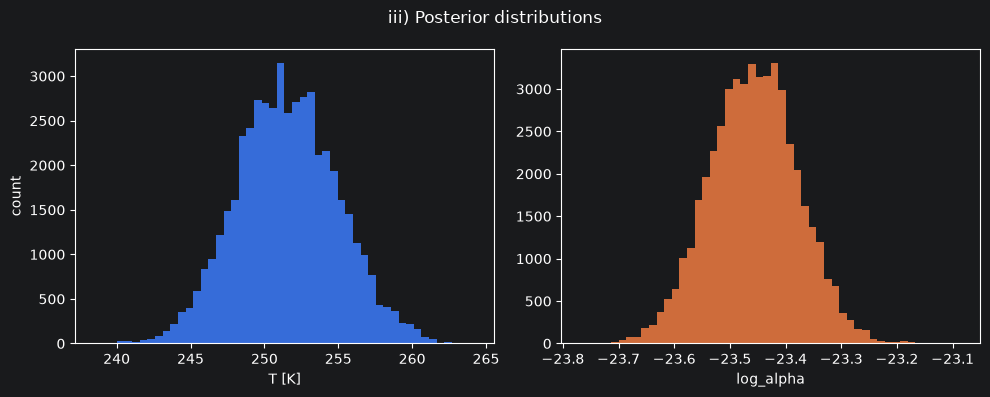

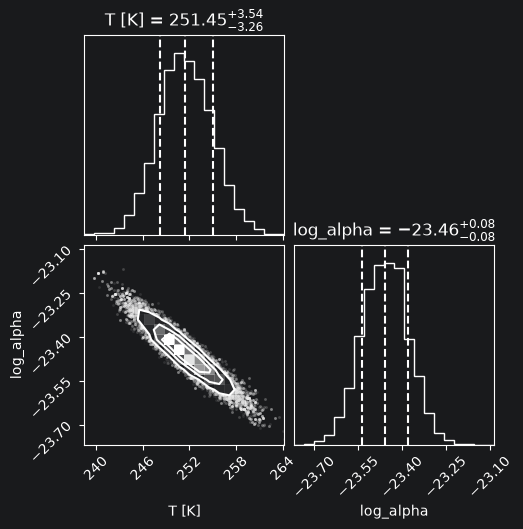

In [26]:
import corner
labels = ["T [K]", "log_alpha"]

# i) burn-in: full trace with the discarded region shaded
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(chain[:, i], lw=0.5)
    ax.axvspan(0, burn_in, color="red", alpha=0.2, label="burn-in" if i == 0 else None)
    ax.set_ylabel(labels[i])
axes[0].legend()
axes[1].set_xlabel("step")
fig.suptitle("i) Burn-in: discarded region shaded")
plt.show()

def running_mean(x, window=200):
    return np.convolve(x, np.ones(window) / window, mode="valid")

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(running_mean(chain_post[:, i]))
    ax.set_ylabel(f"running mean\n{labels[i]}")
axes[1].set_xlabel("step (post burn-in)")
fig.suptitle("ii) Mixing: running mean should be flat")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(chain_post[:, 0], bins=50, color="C0")
axes[0].set_xlabel("T [K]")
axes[0].set_ylabel("count")

axes[1].hist(chain_post[:, 1], bins=50, color="C1")
axes[1].set_xlabel("log_alpha")

fig.suptitle("iii) Posterior distributions")
plt.tight_layout()
plt.show()



fig = corner.corner(chain_post, labels=labels,
                     quantiles=[0.16, 0.5, 0.84], show_titles=True)
plt.show()

## 8*) Bonus: combine multiple chains from independent seeds

chain 0: start T=698.2 K, accept_rate=16.93%
chain 1: start T=259.3 K, accept_rate=17.01%
chain 2: start T=217.1 K, accept_rate=17.20%
chain 3: start T=927.2 K, accept_rate=16.93%


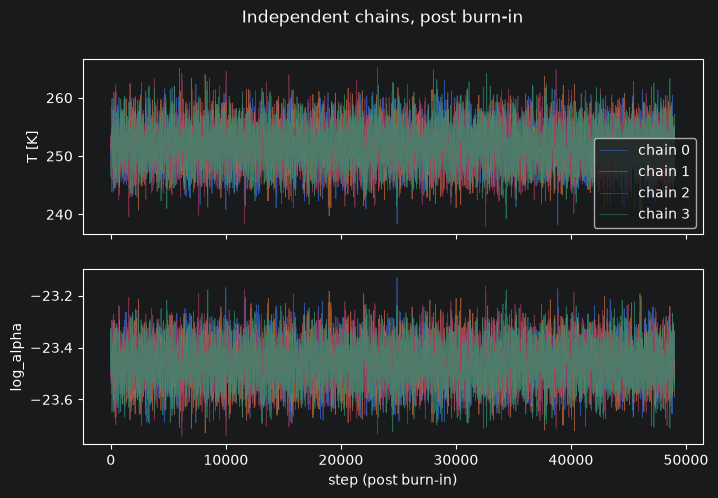

chain 0: median T = 251.5 K, median log_alpha = -23.46
chain 1: median T = 251.6 K, median log_alpha = -23.46
chain 2: median T = 251.5 K, median log_alpha = -23.46
chain 3: median T = 251.6 K, median log_alpha = -23.46
combined 196004 samples from 4 independent chains


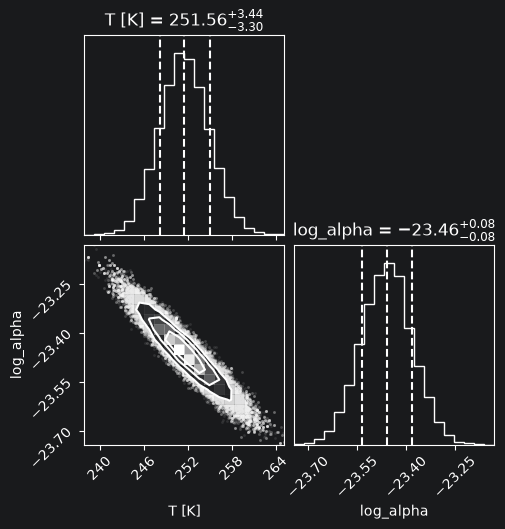

In [27]:
n_chains = 4
n_steps = 50000
burn_in = 1000

rng_init = np.random.default_rng(123)

chains = []
log_posts = []
accept_rates = []

for k in range(n_chains):
    # independent random starting point and RNG seed per chain
    T_start = rng_init.uniform(*T_BOUNDS)
    log_alpha_start = rng_init.uniform(*LOG_ALPHA_BOUNDS)
    start_k = np.array([T_start, log_alpha_start])

    chain_k, log_post_k, accept_k = run_metropolis(
        log_posterior, start_k, proposal_sigma, n_steps,
        seed=1000 + k, args=(wavelength, log_flux, log_flux_err),
    )
    print(f"chain {k}: start T={T_start:.1f} K, accept_rate={accept_k:.2%}")

    chains.append(chain_k[burn_in:])
    log_posts.append(log_post_k[burn_in:])
    accept_rates.append(accept_k)

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for k, chain_k in enumerate(chains):
    axes[0].plot(chain_k[:, 0], lw=0.5, alpha=0.7, label=f"chain {k}")
    axes[1].plot(chain_k[:, 1], lw=0.5, alpha=0.7)
axes[0].set_ylabel("T [K]")
axes[1].set_ylabel("log_alpha")
axes[1].set_xlabel("step (post burn-in)")
axes[0].legend()
fig.suptitle("Independent chains, post burn-in")
plt.show()

# numeric check: per-chain medians should roughly agree
for k, chain_k in enumerate(chains):
    print(f"chain {k}: median T = {np.median(chain_k[:, 0]):.1f} K, "
          f"median log_alpha = {np.median(chain_k[:, 1]):.2f}")

combined_chain = np.concatenate(chains, axis=0)
print(f"combined {len(combined_chain)} samples from {n_chains} independent chains")

fig = corner.corner(combined_chain, labels=labels,
                     quantiles=[0.16, 0.5, 0.84], show_titles=True)
plt.show()

## 9*) Bonus: compare priors on T (log-uniform vs. uniform vs. uniform-in-T^4)

     uniform: accept_rate=17.06%, median T=251.5 K
 log-uniform: accept_rate=17.07%, median T=251.5 K
  uniform-T4: accept_rate=17.02%, median T=251.8 K


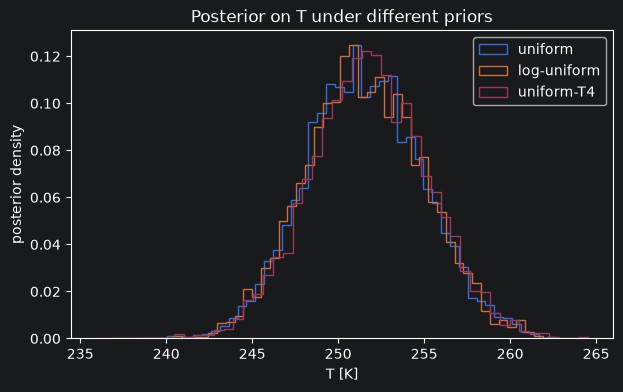

In [30]:
import functools

def log_prior(params, T_prior_type="uniform"):
    """Priors on T (configurable family) and log_alpha (flat), within fixed bounds."""
    T, log_alpha = params
    if not (T_BOUNDS[0] < T < T_BOUNDS[1]):
        return -np.inf
    if not (LOG_ALPHA_BOUNDS[0] < log_alpha < LOG_ALPHA_BOUNDS[1]):
        return -np.inf

    if T_prior_type == "uniform":
        log_prior_T = 0.0
    elif T_prior_type == "log-uniform":
        log_prior_T = -np.log(T)
    elif T_prior_type == "uniform-T4":
        # uniform in T^4 => density in T is the Jacobian d(T^4)/dT = 4 T^3
        log_prior_T = np.log(4.0) + 3.0 * np.log(T)
    else:
        raise ValueError(f"unknown T_prior_type: {T_prior_type}")

    return log_prior_T


def log_posterior_with_prior(params, wavelength, log_flux, log_flux_err, T_prior_type="uniform"):
    lp = log_prior(params, T_prior_type)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params, wavelength, log_flux, log_flux_err)

prior_types = ["uniform", "log-uniform", "uniform-T4"]
prior_chains = {}

for pt in prior_types:
    log_post_fn = functools.partial(log_posterior_with_prior, T_prior_type=pt)
    chain_pt, log_post_pt, accept_pt = run_metropolis(
        log_post_fn, theta0, proposal_sigma, n_steps,
        seed=0, args=(wavelength, log_flux, log_flux_err),
    )
    prior_chains[pt] = chain_pt[burn_in:]
    med_T = np.median(chain_pt[burn_in:, 0])
    print(f"{pt:>12}: accept_rate={accept_pt:.2%}, median T={med_T:.1f} K")

fig, ax = plt.subplots(figsize=(7, 4))
for pt, chain_pt in prior_chains.items():
    ax.hist(chain_pt[:, 0], bins=50, histtype="step", density=True, label=pt)
ax.set_xlabel("T [K]")
ax.set_ylabel("posterior density")
ax.legend()
ax.set_title("Posterior on T under different priors")
plt.show()

## 10*) Bonus: add a quadrature extra-noise term with a log-uniform prior

acceptance rate: 4.60%


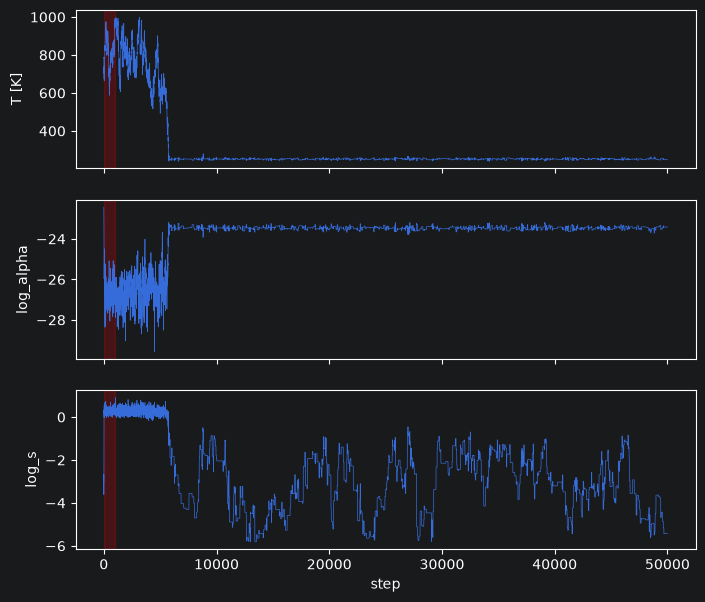

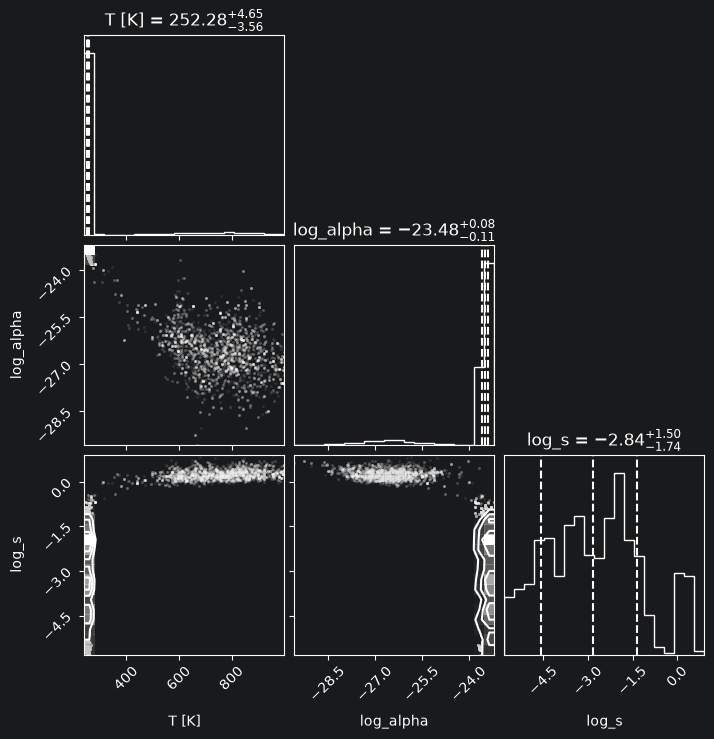

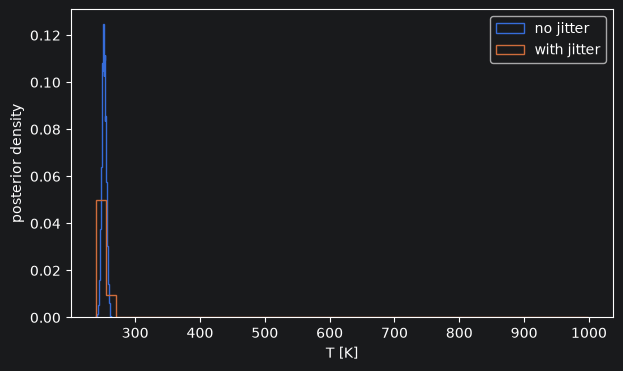

median log_s = -2.84 (s = 1.46e-03)


In [32]:
LOG_S_BOUNDS = (-6.0, 1.0)  # log10(s); s in log-flux units, same scale as log_flux_err


def log_likelihood_jitter(params, wavelength, log_flux, log_flux_err):
    """Gaussian log-likelihood with an extra noise term s added in quadrature
    to the formal errors: sigma_eff^2 = log_flux_err^2 + s^2."""
    T, log_alpha, log_s = params
    model = log_model(wavelength, T, log_alpha)
    s = 10.0 ** log_s
    sigma_eff2 = log_flux_err**2 + s**2
    resid2 = (log_flux - model) ** 2
    return -0.5 * np.sum(resid2 / sigma_eff2 + np.log(2.0 * np.pi * sigma_eff2))


def log_prior_jitter(params):
    """Flat priors on T and log_alpha, plus a flat prior on log_s
    (= log-uniform prior on s itself, since s is a strictly-positive scale term)."""
    T, log_alpha, log_s = params
    if not (T_BOUNDS[0] < T < T_BOUNDS[1]):
        return -np.inf
    if not (LOG_ALPHA_BOUNDS[0] < log_alpha < LOG_ALPHA_BOUNDS[1]):
        return -np.inf
    if not (LOG_S_BOUNDS[0] < log_s < LOG_S_BOUNDS[1]):
        return -np.inf
    return 0.0


def log_posterior_jitter(params, wavelength, log_flux, log_flux_err):
    lp = log_prior_jitter(params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood_jitter(params, wavelength, log_flux, log_flux_err)

# start near the single-chain Part 6 result, with log_s initialized small
theta0_jitter = np.array([theta0[0], theta0[1], -3.0])
proposal_sigma_jitter = np.array([20.0, 0.5, 0.5])  # tune as in Part 5

chain_jitter, log_post_jitter, accept_jitter = run_metropolis(
    log_posterior_jitter, theta0_jitter, proposal_sigma_jitter, n_steps,
    seed=0, args=(wavelength, log_flux, log_flux_err),
)
print(f"acceptance rate: {accept_jitter:.2%}")

chain_jitter_post = chain_jitter[burn_in:]

labels_jitter = ["T [K]", "log_alpha", "log_s"]

fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(chain_jitter[:, i], lw=0.5)
    ax.axvspan(0, burn_in, color="red", alpha=0.2)
    ax.set_ylabel(labels_jitter[i])
axes[-1].set_xlabel("step")
plt.show()

fig = corner.corner(chain_jitter_post, labels=labels_jitter, bins= 20, quantiles=[0.16, 0.5, 0.84], show_titles=True)
plt.show()

# compare T posterior with vs. without the jitter term
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(chain_post[:, 0], bins=50, histtype="step", density=True, label="no jitter")
ax.hist(chain_jitter_post[:, 0], bins=50, histtype="step", density=True, label="with jitter")
ax.set_xlabel("T [K]")
ax.set_ylabel("posterior density")
ax.legend()
plt.show()

print(f"median log_s = {np.median(chain_jitter_post[:, 2]):.2f} "
      f"(s = {10**np.median(chain_jitter_post[:, 2]):.2e})")

## 11) Final result

Report median +/- 1 sigma quantiles for T (and alpha). Compare to the literature value from Luhman (2014), 1408.5424v3.pdf.